# **MODULE 35.2 — FRAME-LEVEL AND UTTERANCE-LEVEL FEATURES**



Must Know

Practical Lab 35B



## **1. Frame-level features vs. utterance-level features**

First, understand these two levels.

### **Frame-level features**

Instead of analysing an entire recording as one signal, we divide it into smaller frames and calculate features for each frame.

Suppose we have a 4-second recording.

Using:

- Sampling rate = 16,000 Hz
- Frame length = 25 ms
- Hop length = 10 ms

We calculate RMS and ZCR repeatedly across the recording.

![Speech Recognition — Feature Extraction MFCC & PLP | by Jonathan Hui | Medium](https://images.openai.com/static-rsc-4/Bq5y_zEqzl6Hs0ddHi0yxGqY2tNRsFYpqj3-rKIJy5WflNkylZ7wO3F66sl76Ry5Mg3DWMdlTlzOcbUobgTcNGdRHitoPmJpEU-VtQfgIO97zvAOsw8X_IyTsSfJogA-GqatrB1mch6WVxtXzC6Qg87IwOzGsa-d5NZlkrkQhkM?purpose=inline)

[jonathan-hui.medium.com](https://jonathan-hui.medium.com/speech-recognition-feature-extraction-mfcc-plp-5455f5a69dd9?utm_source=chatgpt.com)

Each frame produces feature values.

For example:

| Frame | Time   | RMS  | ZCR  |
| ----- | ------ | ---- | ---- |
| 1     | 0.00 s | 0.12 | 0.08 |
| 2     | 0.01 s | 0.15 | 0.10 |
| 3     | 0.02 s | 0.19 | 0.12 |
| 4     | 0.03 s | 0.17 | 0.09 |
| 5     | 0.04 s | 0.11 | 0.07 |

These are frame-level features.

The important point: **each frame describes a small portion of the recording, not the entire recording.**

### **Utterance-level features**

An utterance is the complete speech segment we want to analyse.

Suppose we have 400 frame-level RMS values.

We can calculate their:

- Mean
- Standard deviation
- Minimum
- Maximum
- Range
- Percentiles

These statistics summarize the entire utterance.

For example:

| Utterance feature  | RMS  |
| ------------------ | ---- |
| Mean               | 0.15 |
| Standard deviation | 0.04 |
| Minimum            | 0.02 |
| Maximum            | 0.28 |
| Range              | 0.26 |

These are utterance-level features.

![8.6. Paralinguistic speech processing — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/xVyax-EjxhACrij-mLRP4wyL5_Y_qiPtLOXmymBi7BsdznlNYma0EwcKYEm-HSKlE-M8JsndOSeRscnAI14U1pq7DJD2yF9po-bPzOKuM9PHAhuKrC_BwoshcyGBkLmwCSol7XTPcyvn9zNqQljW5MwoXjaLbb6rFC5Jkt9OI8Q?purpose=inline)

[speechprocessingbook.aalto.fi](https://speechprocessingbook.aalto.fi/Recognition/Paralinguistic_speech_processing.html?utm_source=chatgpt.com)

**Remember:**

- Frame-level = What is happening at each moment?
- Utterance-level = What are the overall characteristics of the recording?

## **2. Short-time feature sequences**

Must Know

Let's understand why we calculate features frame by frame.

Consider a person speaking angrily:

```
Time →
0s        1s        2s        3s        4s

RMS:
Low → Medium → High → High → Medium
```

The RMS changes over time.

Instead of getting just one RMS value, we obtain a sequence:

\\[ RMS = [0.05, 0.08, 0.12, 0.21, 0.25, 0.18, 0.10] \\]

This sequence is called a **short-time feature sequence**.

The same approach works for ZCR:

\\[ ZCR = [0.04, 0.06, 0.08, 0.12, 0.15, 0.11, 0.07] \\]

We can visualize these sequences to understand how the voice changes throughout the utterance.

### **Why is this useful for SER?**

Emotion is not necessarily constant throughout an utterance.

For example:

- A person may start speaking calmly.
- Their voice may become louder.
- They may finish with an emotionally intense expression.

A single average cannot describe this progression.

## **3. Statistical pooling**

Must Know

We have a sequence of frame-level values. How do we convert it into a fixed-length feature vector?

We use statistical pooling.

Suppose:

\\[ X = [2,4,6,8,10] \\]

We can calculate several statistics.

### **3.1 Mean**

The mean represents the average value.

\\[ \mu = \frac{1}{N}\sum\_{i=1}^{N}x_i \\]

Example:

\\[ \mu = \frac{2+4+6+8+10}{5}=6 \\]

For RMS, mean RMS describes the average frame-level RMS across the recording.

### **3.2 Standard deviation**

Standard deviation measures how much the values vary around their mean.

\\[ \sigma = \sqrt{\frac{1}{N}\sum\_{i=1}^{N}(x_i-\mu)^2} \\]

For our example:

\\[ \sigma = \sqrt{8} \approx 2.83 \\]

A higher standard deviation indicates greater variation.

In SER, this can help describe how consistently or dynamically a vocal characteristic changes.

### **3.3 Minimum and maximum**

Minimum:

\\[ x\_{\min} = \min(X) \\]

Maximum:

\\[ x\_{\max} = \max(X) \\]

For our example:

- Minimum = 2
- Maximum = 10

These describe the lowest and highest observed values.

### **3.4 Range**

Range describes the difference between the maximum and minimum.

\\[ Range = x\_{\max}-x\_{\min} \\]

\\[ Range=10-2=8 \\]

### **3.5 Percentiles**

Percentiles describe the distribution of values.

For example:

- 25th percentile: 25% of values are at or below this value.
- 50th percentile: median.
- 75th percentile: 75% of values are at or below this value.

Python:

```
np.percentile(values, [25, 50, 75])
```

Percentiles are useful because extreme values can sometimes distort the interpretation of the mean.

### **Statistical pooling summary**

| Statistic          | What it tells us                          |
| ------------------ | ----------------------------------------- |
| Mean               | Average behaviour                         |
| Standard deviation | Degree of variation                       |
| Minimum            | Lowest observed value                     |
| Maximum            | Highest observed value                    |
| Range              | Total spread                              |
| Percentiles        | Distribution of values                    |
| Median             | Central value, less sensitive to outliers |

## **4. Why averaging every frame can discard emotional dynamics**

Must Know

This is one of the most important concepts in this module.

Imagine two utterances.

**Utterance A — Consistent energy**

RMS sequence

# **0.10, 0.10, 0.10, 0.10**

Mean = 0.10

**Utterance B — Changing energy**

RMS sequence

# **0.02, 0.02, 0.18, 0.18**

Mean = 0.10

Both have exactly the same mean.

But their temporal behaviour is completely different!

- A has consistent energy.
- B has a significant change in energy.

If we retain only the mean, we lose this distinction.

Adding standard deviation helps:

| Feature            | Utterance A | Utterance B |
| ------------------ | ----------- | ----------- |
| Mean               | 0.10        | 0.10        |
| Standard deviation | 0.00        | 0.08        |
| Minimum            | 0.10        | 0.02        |
| Maximum            | 0.10        | 0.18        |

However, even mean and standard deviation do not preserve the exact order of events.

For example:

```
A = [0.02, 0.02, 0.18, 0.18]B = [0.18, 0.18, 0.02, 0.02]
```

Both have identical statistical summaries, but opposite temporal progression.

**Research takeaway:** Statistical pooling captures distributional characteristics, but not the complete temporal structure. Later, sequence models such as CNN-LSTM or other temporal architectures can learn patterns across frames.

# **5. Time-domain features we will retain**

We'll focus on four measurements for our SER project.

## **5.1 RMS Energy**

Must Know

RMS stands for Root Mean Square.

It measures the signal's average magnitude over a frame, accounting for positive and negative samples.

\\[ RMS = \sqrt{\frac{1}{N}\sum\_{n=1}^{N}x[n]^2} \\]

Intuition:

- Higher RMS → greater signal energy.
- Lower RMS → lower signal energy.

But remember, RMS is affected by microphone distance, recording gain, and background noise. It is not a direct measurement of emotion or perceived loudness.

## **5.2 Short-time energy**

Must Know

Short-time energy is calculated by summing the squared samples in each frame.

\\[ E = \sum\_{n=1}^{N}x[n]^2 \\]

Compare it with RMS:

\\[ RMS = \sqrt{\frac{E}{N}} \\]

Therefore:

\\[ E=N \times RMS^2 \\]

**Important distinction:** Short-time energy depends on frame length, whereas RMS is normalized by the number of samples.

If frame length is fixed, they are mathematically related and highly redundant. We'll retain energy statistics for learning purposes but avoid assuming they provide independent information.

## **5.3 Zero Crossing Rate (ZCR)**

Must Know

ZCR measures how frequently the signal crosses zero.

\\[ ZCR = \frac{1}{2N} \sum\_{n=1}^{N-1} \left|\operatorname{sgn}(x[n])-\operatorname{sgn}(x[n-1])\right| \\]

Intuition:

- Higher ZCR → more frequent zero crossings.
- Lower ZCR → fewer zero crossings.

ZCR can provide information about signal characteristics such as noisiness and spectral content.

It should not be interpreted as a direct indicator of anger, happiness, or sadness.

![3.11. Zero-crossing rate — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/F60WI7yhRTFq-R7A5aIqZSdCiSfGLgrFcpwPHc9c3WRkewPBkyeFZ0sN3vK_L9X-ud40sZsasEq72xiE45GCFOsgu6lVmIXwsA99AfXJOgVRR-xtTZuJVogzEjPoCRmZMN5T0Gair42j-XZGD7Lpptc2OQZnNOdFzo5c5wvY_zE?purpose=inline)

[speechprocessingbook.aalto.fi](https://speechprocessingbook.aalto.fi/Representations/Zero-crossing_rate.html?utm_source=chatgpt.com)

## **5.4 Duration and silence-related measurements**

Must Know

These measurements provide additional information about speaking behaviour.

| Feature                   | Meaning                                    |
| ------------------------- | ------------------------------------------ |
| Total duration            | Complete recording duration                |
| Active speech duration    | Estimated duration containing speech       |
| Silence duration          | Estimated duration without speech          |
| Silence ratio             | Silence duration divided by total duration |
| Number of speech segments | Number of detected speech regions          |

For example:

\\[ SilenceRatio = \frac{SilenceDuration}{TotalDuration} \\]

If a 10-second recording contains 3 seconds of detected silence:

\\[ SilenceRatio=\frac{3}{10}=0.3 \\]

That means 30% of the recording was classified as silence.

Note that this depends on the VAD or silence-detection method and threshold.

---

## **What you should remember**

1. Frame-level features describe short sections of audio.
2. Utterance-level features summarize the entire recording.
3. Statistical pooling converts variable-length feature sequences into fixed-length vectors.
4. Mean alone cannot describe temporal variation.
5. RMS, ZCR, energy, duration, and silence measurements provide useful time-domain information.
6. Statistical features do not preserve the order of emotional events.

---

In [1]:
def preprocess_audio(
    file_path,
    target_sr=16000,
    target_duration=4,
    mono=True,
    normalize=False,
    crop_strategy="center"
):

    # 1. Load original audio
    audio, original_sr = sf.read(file_path)

    # 2. Inspect original properties
    original_shape = audio.shape
    original_channels = 1 if audio.ndim == 1 else audio.shape[1]

    if audio.ndim == 2:
        original_audio = audio.copy()
    else:
        original_audio = audio.copy()

    original_duration = len(audio) / original_sr
    original_peak = float(np.max(np.abs(audio))) if audio.size else 0.0

    # 3. Convert stereo to mono when requested
    if mono and audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    # 4. Resample only when required
    if original_sr != target_sr:
        if audio.ndim == 1:
            audio = librosa.resample(
                audio.astype(np.float32),
                orig_sr=original_sr,
                target_sr=target_sr
            )
        else:
            audio = librosa.resample(
                audio.astype(np.float32),
                orig_sr=original_sr,
                target_sr=target_sr,
                axis=0
            )

    # 5. Calculate target number of samples
    target_samples = int(target_sr * target_duration)

    # 6. Trim or pad
    if len(audio) > target_samples:

        if crop_strategy == "center":
            start = (len(audio) - target_samples) // 2

        elif crop_strategy == "start":
            start = 0

        elif crop_strategy == "end":
            start = len(audio) - target_samples

        else:
            raise ValueError("Invalid crop_strategy")

        audio = audio[start:start + target_samples]

    elif len(audio) < target_samples:

        padding = target_samples - len(audio)

        if audio.ndim == 1:
            audio = np.pad(audio, (0, padding))
        else:
            audio = np.pad(
                audio,
                ((0, padding), (0, 0))
            )

    # 7. Optional peak normalization
    processed_peak_before_normalization = (
        float(np.max(np.abs(audio))) if audio.size else 0.0
    )

    if normalize and processed_peak_before_normalization > 0:
        audio = audio / processed_peak_before_normalization

    # 8. Collect metadata
    metadata = {
        "original_sample_rate": original_sr,
        "target_sample_rate": target_sr,
        "original_channels": original_channels,
        "original_shape": original_shape,
        "original_duration": original_duration,
        "original_peak": original_peak,
        "processed_duration": len(audio) / target_sr,
        "processed_samples": len(audio),
        "processed_peak": float(np.max(np.abs(audio))),
        "normalization_applied": normalize,
        "crop_strategy": crop_strategy
    }

    return audio.astype(np.float32), metadata

In [2]:
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import soundfile as sf 

TARGET_SR = 16000

FRAME_LENGTH = 400   # 25 ms at 16 kHz
HOP_LENGTH = 160     # 10 ms at 16 kHz

In [3]:
audio, metadata = preprocess_audio(
    "audio/raw/sample-speech-1m.mp3",
    target_sr=TARGET_SR,
    target_duration=4,
    mono=True,
    normalize=False
)

In [4]:
# Calculate frame-level RMS
rms = librosa.feature.rms(
    y=audio,
    frame_length=FRAME_LENGTH,
    hop_length=HOP_LENGTH
)[0]

print("RMS shape:", rms.shape)
print(rms[:10])

RMS shape: (401,)
[0.13570714 0.18862599 0.20471211 0.19105925 0.18768033 0.17685847
 0.13624047 0.08320665 0.06427136 0.05750881]


In [5]:
# Calculate frame-level ZCR
zcr = librosa.feature.zero_crossing_rate(
    y=audio,
    frame_length=FRAME_LENGTH,
    hop_length=HOP_LENGTH
)[0]

print("ZCR shape:", zcr.shape)
print(zcr[:10])

ZCR shape: (401,)
[0.02   0.045  0.0675 0.0875 0.0875 0.0625 0.03   0.02   0.02   0.03  ]


In [6]:
# Calculate short-time energy
short_time_energy = (rms ** 2) * FRAME_LENGTH

print("Energy shape:", short_time_energy.shape)
print(short_time_energy[:10])

Energy shape: (401,)
[ 7.366571  14.231905  16.76282   14.601454  14.089563  12.511568
  7.4245863  2.7693388  1.6523231  1.3229053]


In [7]:
# Calculate utterance-level statistics
def calculate_statistics(values, prefix):

    return {
        f"{prefix}_mean": np.mean(values),
        f"{prefix}_std": np.std(values),
        f"{prefix}_min": np.min(values),
        f"{prefix}_max": np.max(values),
        f"{prefix}_range": np.ptp(values),
        f"{prefix}_median": np.median(values),
        f"{prefix}_p25": np.percentile(values, 25),
        f"{prefix}_p75": np.percentile(values, 75)
    }

In [13]:
features = {}

features.update(calculate_statistics(rms, "rms"))
features.update(calculate_statistics(zcr, "zcr"))
features.update(calculate_statistics(short_time_energy, "energy"))

for key,item in features.items():
    print(f"{key:15} --> {item:.5f}")

rms_mean        --> 0.13018
rms_std         --> 0.08330
rms_min         --> 0.00006
rms_max         --> 0.25835
rms_range       --> 0.25829
rms_median      --> 0.17333
rms_p25         --> 0.03357
rms_p75         --> 0.19776
zcr_mean        --> 0.13153
zcr_std         --> 0.19126
zcr_min         --> 0.01750
zcr_max         --> 0.84500
zcr_range       --> 0.82750
zcr_median      --> 0.04750
zcr_p25         --> 0.02750
zcr_p75         --> 0.12000
energy_mean     --> 9.55375
energy_std      --> 7.67906
energy_min      --> 0.00000
energy_max      --> 26.69861
energy_range    --> 26.69860
energy_median   --> 12.01694
energy_p25      --> 0.45088
energy_p75      --> 15.64295


In [14]:
# Duration and silence-related measurements
# Frame-level RMS threshold
silence_threshold = 0.01

silent_frames = rms < silence_threshold

total_frames = len(rms)

silence_ratio = np.mean(silent_frames)

speech_ratio = 1 - silence_ratio

total_duration = len(audio) / TARGET_SR

features.update({
    "duration": total_duration,
    "silence_ratio": silence_ratio,
    "speech_ratio": speech_ratio,
    "estimated_silence_duration": silence_ratio * total_duration,
    "estimated_active_duration": speech_ratio * total_duration
})

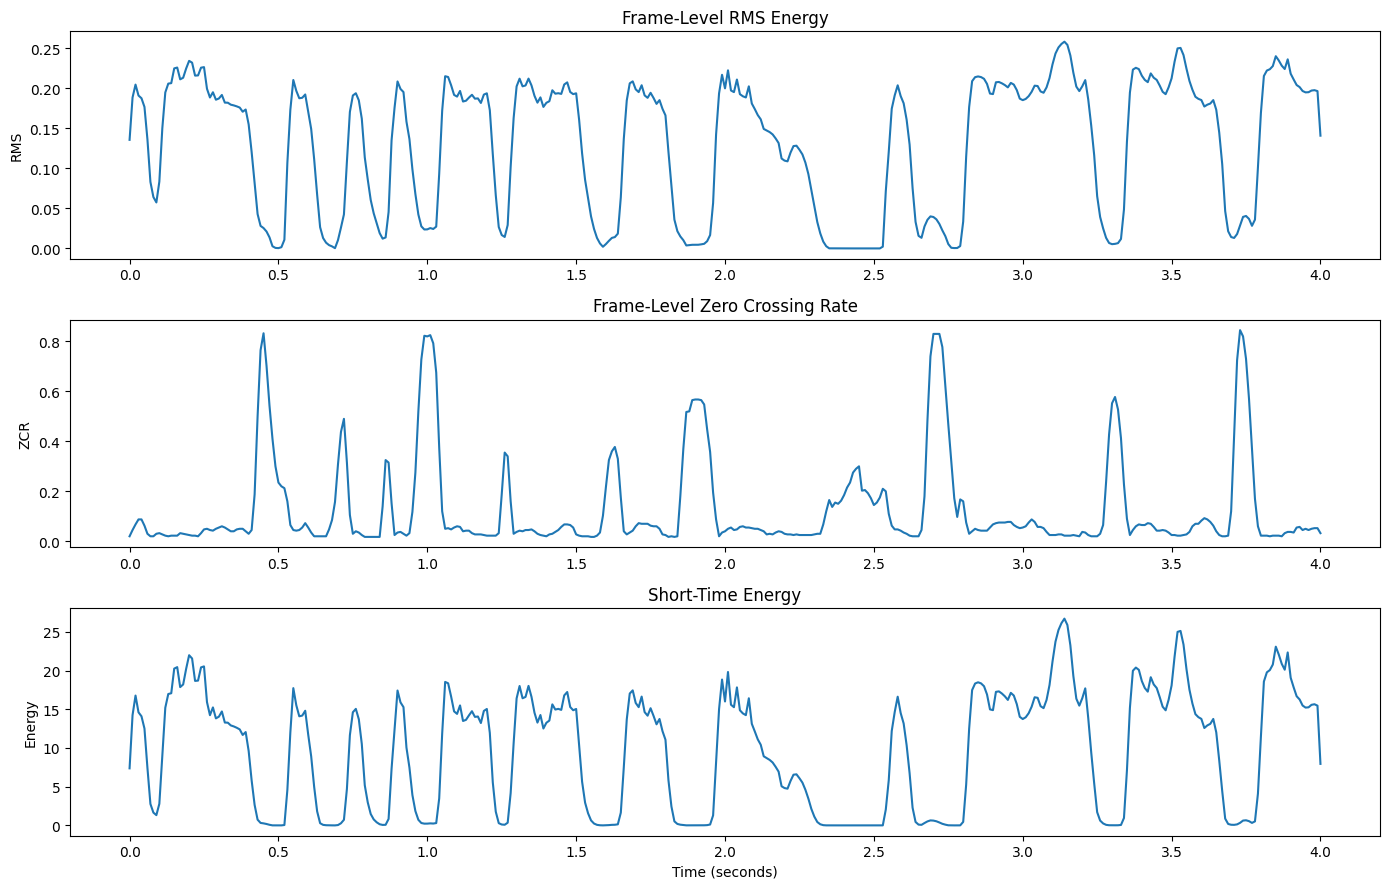

In [15]:
times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=TARGET_SR,
    hop_length=HOP_LENGTH
)

fig, axes = plt.subplots(3, 1, figsize=(14, 9))

axes[0].plot(times, rms)
axes[0].set_title("Frame-Level RMS Energy")
axes[0].set_ylabel("RMS")

axes[1].plot(times, zcr)
axes[1].set_title("Frame-Level Zero Crossing Rate")
axes[1].set_ylabel("ZCR")

axes[2].plot(times, short_time_energy)
axes[2].set_title("Short-Time Energy")
axes[2].set_ylabel("Energy")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [16]:
# reusable code 

def extract_time_domain_features(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=TARGET_SR,
        mono=True
    )

    rms = librosa.feature.rms(
        y=audio,
        frame_length=FRAME_LENGTH,
        hop_length=HOP_LENGTH
    )[0]

    zcr = librosa.feature.zero_crossing_rate(
        y=audio,
        frame_length=FRAME_LENGTH,
        hop_length=HOP_LENGTH
    )[0]

    energy = (rms ** 2) * FRAME_LENGTH

    features = {}

    features.update(calculate_statistics(rms, "rms"))
    features.update(calculate_statistics(zcr, "zcr"))
    features.update(calculate_statistics(energy, "energy"))

    silence_ratio = np.mean(rms < 0.01)

    duration = len(audio) / sr

    features.update({
        "duration": duration,
        "silence_ratio": silence_ratio,
        "estimated_silence_duration": silence_ratio * duration,
        "estimated_active_duration": (1 - silence_ratio) * duration
    })

    features["filename"] = Path(file_path).name

    return features

In [20]:
from itertools import chain

audio_folder = Path("audio/raw")

all_features = []

for file_path in chain(audio_folder.glob("*.mp3"),audio_folder.glob("*.wav")) :

    feature_row = extract_time_domain_features(file_path)

    all_features.append(feature_row)

df = pd.DataFrame(all_features)

df.head()

,rms_mean,rms_std,rms_min,rms_max,rms_range,rms_median,rms_p25,rms_p75,zcr_mean,zcr_std,...,energy_max,energy_range,energy_median,energy_p25,energy_p75,duration,silence_ratio,estimated_silence_duration,estimated_active_duration,filename
0,0.070582,0.030868,0.019522,0.237701,0.218180,0.066443,0.050210,0.082057,0.108306,0.050186,...,22.600775,22.448338,1.765856,1.008419,2.693338,54.949937,0.000000,0.000000,54.949937,sample-55s.mp3
1,0.128043,0.085472,0.000046,0.269056,0.269009,0.162250,0.032354,0.200619,0.144065,0.204795,...,28.956387,28.956387,10.529973,0.418723,16.099186,60.005437,0.148809,8.929321,51.076116,sample-speech-1m.mp3
2,0.230050,0.047593,0.013715,0.264684,0.250969,0.237895,0.236592,0.237907,0.091772,0.005372,...,28.023109,27.947865,22.637674,22.390265,22.639803,1.500000,0.000000,0.000000,1.500000,01_vowel_ah.wav
3,0.082092,0.017528,0.006159,0.096134,0.089975,0.086985,0.083819,0.089750,0.644628,0.046207,...,3.696724,3.681551,3.026532,2.810219,3.221993,1.200000,0.016529,0.019835,1.180165,02_consonant_s.wav
4,0.169477,0.122985,0.000000,0.333104,0.333104,0.094667,0.087925,0.309714,0.316450,0.300210,...,44.383228,44.383228,3.584720,3.092324,38.369087,1.800000,0.116022,0.208840,1.591160,03_voiced_then_unvoiced.wav
